<a href="https://colab.research.google.com/github/Yahya1805/machine-learning_2026/blob/main/ML_JS13_10_Artificial_Neural_Network_(ANN)_dan_Evaluasi_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAPORAN TUGAS PRAKTIKUM JS13 – KLASIFIKASI ANGKA TULISAN TANGAN MENGGUNAKAN ANN (MNIST) & REGRESI ESTIMASI SELADA

**Identitas Mahasiswa:**
- **Nama:** M.Yahya Irvansyah
- **Kelas:** TI-3G
- **NIM:** 244107020032

---

## 1. TUJUAN PRAKTIKUM
1. Memahami penerapan Artificial Neural Network (ANN) untuk klasifikasi gambar berbasis pixel.
2. Menguasai langkah preprocessing gambar pada dataset MNIST (normalisasi skala pixel dan one-hot encoding).
3. Membangun model ANN menggunakan TensorFlow/Keras dengan variasi arsitektur hidden layer.
4. Melakukan training, evaluasi, dan diagnosis performa model.
5. Membandingkan pengaruh jumlah neuron, jumlah hidden layer, dan fungsi aktivasi (Sigmoid vs ReLU) terhadap akurasi serta waktu eksekusi training.
6. Menerapkan ANN Regresi pada dataset riil selada (`lettuce_dataset_updated.csv`) untuk estimasi masa panen (*Growth Days*) menggunakan pemisahan grup independen guna mencegah kebocoran data (*data leakage*).

## 2. IMPORT LIBRARY
Kita mengimpor seluruh pustaka yang diperlukan untuk pengerjaan dataset MNIST maupun dataset Selada di awal program agar terstruktur.

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

# Scikit-learn untuk evaluasi dan utilities data kelompok
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, mean_squared_error,
    mean_absolute_error, r2_score
)

# TensorFlow & Keras
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.datasets import mnist

# Atur random seed agar hasil eksperimen konsisten
np.random.seed(42)
tf.random.set_seed(42)

print("Seluruh library berhasil dimuat dengan sukses!")

Seluruh library berhasil dimuat dengan sukses!


## 3. DATASET MNIST & VISUALISASI
Dataset MNIST (Modified National Institute of Standards and Technology) merupakan dataset standar emas untuk pengenalan gambar tingkat pemula. MNIST terdiri dari 60.000 data latih dan 10.000 data uji berupa gambar grayscale berukuran 28x28 piksel dari angka tulisan tangan 0 hingga 9.

In [20]:
# Load dataset MNIST bawaan Keras
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = mnist.load_data()

# Tampilkan dimensi data latih dan data uji
print("=== Dimensi Data MNIST ===")
print(f"Data Latih (Features): {X_train_raw.shape}")
print(f"Label Latih         : {y_train_raw.shape}")
print(f"Data Uji (Features)  : {X_test_raw.shape}")
print(f"Label Uji           : {y_test_raw.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
=== Dimensi Data MNIST ===
Data Latih (Features): (60000, 28, 28)
Label Latih         : (60000,)
Data Uji (Features)  : (10000, 28, 28)
Label Uji           : (10000,)


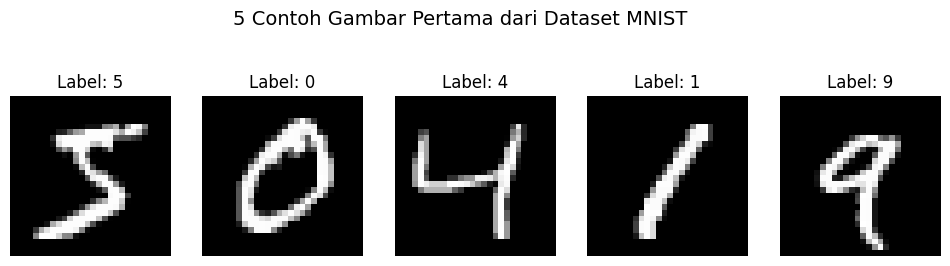

In [21]:
# Visualisasi 5 contoh gambar MNIST beserta label aslinya
plt.figure(figsize=(12, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_train_raw[i], cmap='gray')
    plt.title(f"Label: {y_train_raw[i]}")
    plt.axis('off')
plt.suptitle("5 Contoh Gambar Pertama dari Dataset MNIST", fontsize=14, y=1.05)
plt.show()

/tmp/ipykernel_2767/2838715673.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(dist_dict.keys()), y=list(dist_dict.values()), palette="viridis")


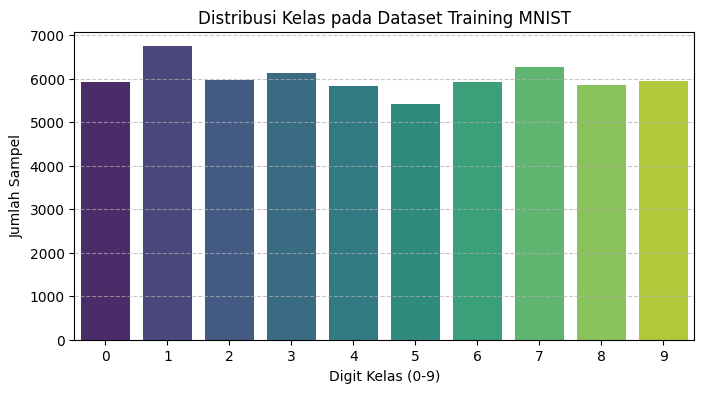

Kelas 0: 5923 gambar
Kelas 1: 6742 gambar
Kelas 2: 5958 gambar
Kelas 3: 6131 gambar
Kelas 4: 5842 gambar
Kelas 5: 5421 gambar
Kelas 6: 5918 gambar
Kelas 7: 6265 gambar
Kelas 8: 5851 gambar
Kelas 9: 5949 gambar


In [22]:
# Periksa distribusi jumlah masing-masing kelas
unique, counts = np.unique(y_train_raw, return_counts=True)
dist_dict = dict(zip(unique, counts))

plt.figure(figsize=(8, 4))
sns.barplot(x=list(dist_dict.keys()), y=list(dist_dict.values()), palette="viridis")
plt.title("Distribusi Kelas pada Dataset Training MNIST")
plt.xlabel("Digit Kelas (0-9)")
plt.ylabel("Jumlah Sampel")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

for digit, count in dist_dict.items():
    print(f"Kelas {digit}: {count} gambar")

## 4. PREPROCESSING DATA MNIST
Sebelum melatih model ANN, kita perlu menormalisasikan nilai piksel gambar agar berada pada rentang $[0, 1]$ (pembagian dengan 255.0) dan mengubah label kelas tunggal menjadi representasi One-Hot Encoding berukuran 10 kelas menggunakan `to_categorical()`.

In [23]:
# 1. Normalisasi nilai piksel
X_train = X_train_raw / 255.0
X_test = X_test_raw / 255.0

# 2. One-Hot Encoding untuk label kelas
y_train = to_categorical(y_train_raw, num_classes=10)
y_test = to_categorical(y_test_raw, num_classes=10)

print("=== Dimensi Data Pasca-Preprocessing ===")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape : {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape : {y_test.shape}")

=== Dimensi Data Pasca-Preprocessing ===
X_train shape: (60000, 28, 28)
X_test shape : (10000, 28, 28)
y_train shape: (60000, 10)
y_test shape : (10000, 10)


## 5. MODEL ANN KONFIGURASI AWAL
Kita merancang model ANN dengan struktur sekuensial:
- `Flatten()` mengubah matriks gambar $28 \times 28$ piksel menjadi 1D array sepanjang 784 fitur.
- `Hidden Layer 1`: 128 neuron dengan aktivasi ReLU.
- `Hidden Layer 2`: 64 neuron dengan aktivasi ReLU.
- `Output Layer`: 10 neuron dengan fungsi aktivasi Softmax untuk klasifikasi multi-kelas.

In [24]:
# Membangun arsitektur model awal
model_awal = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model_awal.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_awal.summary()

# Latih model awal dan ukur waktu training menggunakan time.perf_counter()
t_start = time.perf_counter()
hist_awal = model_awal.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)
t_end = time.perf_counter()
time_awal = t_end - t_start

print(f"\nWaktu training Model Awal: {time_awal:.2f} detik")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8988 - loss: 0.3532 - val_accuracy: 0.9635 - val_loss: 0.1371
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9584 - loss: 0.1425 - val_accuracy: 0.9710 - val_loss: 0.1038
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9712 - loss: 0.0974 - val_accuracy: 0.9727 - val_loss: 0.0943
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9791 - loss: 0.0719 - val_accuracy: 0.9738 - val_loss: 0.0876
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9839 - loss: 0.0551 - val_accuracy: 0.9742 - val_loss: 0.0879
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9881 - loss: 0.0426 - val_accuracy: 0.9750 - val_loss: 0.0867
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9910 - loss: 0.0336 - val_accuracy: 0.9742 - val_loss: 0.0886
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9926 - loss: 0.0275 - val_accuracy: 0

In [25]:
# Evaluasi Model Awal pada data test
loss_awal_test, acc_awal_test = model_awal.evaluate(X_test, y_test, verbose=0)
print(f"=== Hasil Evaluasi Model Awal ===")
print(f"Test Loss    : {loss_awal_test:.4f}")
print(f"Test Accuracy: {acc_awal_test:.4f}")

=== Hasil Evaluasi Model Awal ===
Test Loss    : 0.1019
Test Accuracy: 0.9722


## 6. EKSPERIMEN A – PERUBAHAN JUMLAH NEURON
Pada eksperimen ini, kita membandingkan Model Awal (128-64 neuron) dengan Model B yang memiliki jumlah kapasitas neuron yang lebih besar pada hidden layer-nya (256-128 neuron).

In [26]:
# Membangun Model Eksperimen A (256-128 neuron)
model_exp_neuron = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model_exp_neuron.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Latih Model B
t_start = time.perf_counter()
hist_exp_neuron = model_exp_neuron.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)
t_end = time.perf_counter()
time_exp_neuron = t_end - t_start

# Evaluasi Model B
loss_exp_n_test, acc_exp_n_test = model_exp_neuron.evaluate(X_test, y_test, verbose=0)
print(f"\nWaktu training Model Eksperimen A (256-128): {time_exp_neuron:.2f} detik")
print(f"Test Accuracy Model Eksperimen A: {acc_exp_n_test:.4f}")

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9161 - loss: 0.2923 - val_accuracy: 0.9673 - val_loss: 0.1128
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.9660 - loss: 0.1139 - val_accuracy: 0.9737 - val_loss: 0.0887
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.9783 - loss: 0.0740 - val_accuracy: 0.9763 - val_loss: 0.0799
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9855 - loss: 0.0501 - val_accuracy: 0.9765 - val_loss: 0.0761
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9901 - loss: 0.0354 - val_accuracy: 0.9768 - val_loss: 0.0763
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9929 - loss: 0.0257 - val_accuracy: 0.9783 - val_loss: 0.0801
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9940 - loss: 0.0208 - val_accuracy: 0.9737 - val_loss: 0.0868
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9948 - loss: 0.0178 - val_accuracy

## 7. EKSPERIMEN B – PENAMBAHAN HIDDEN LAYER
Kita membandingkan Model Awal (2 hidden layer: 128-64) dengan model baru yang ditambahkan 1 hidden layer tambahan (3 hidden layer: 128-64-32 neuron).

In [27]:
# Membangun Model Eksperimen B (128-64-32 neuron)
model_exp_layer = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(10, activation='softmax')
])

model_exp_layer.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Latih Model Eksperimen B
t_start = time.perf_counter()
hist_exp_layer = model_exp_layer.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)
t_end = time.perf_counter()
time_exp_layer = t_end - t_start

# Evaluasi Model Eksperimen B
loss_exp_l_test, acc_exp_l_test = model_exp_layer.evaluate(X_test, y_test, verbose=0)
print(f"\nWaktu training Model Eksperimen B (128-64-32): {time_exp_layer:.2f} detik")
print(f"Test Accuracy Model Eksperimen B: {acc_exp_l_test:.4f}")

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8894 - loss: 0.3820 - val_accuracy: 0.9587 - val_loss: 0.1396
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9584 - loss: 0.1402 - val_accuracy: 0.9665 - val_loss: 0.1068
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9716 - loss: 0.0964 - val_accuracy: 0.9703 - val_loss: 0.0952
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9782 - loss: 0.0718 - val_accuracy: 0.9735 - val_loss: 0.0897
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9829 - loss: 0.0554 - val_accuracy: 0.9732 - val_loss: 0.0938
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9871 - loss: 0.0433 - val_accuracy: 0.9713 - val_loss: 0.1036
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9900 - loss: 0.0345 - val_accuracy: 0.9730 - val_loss: 0.1039
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9906 - loss: 0.0298 - val_accuracy: 0

## 8. EKSPERIMEN C – SIGMOID VS RELU
Kita membandingkan performa model dengan arsitektur 128-64 neuron menggunakan aktivasi **Sigmoid** dengan model awal yang menggunakan aktivasi **ReLU**.

In [28]:
# Membangun Model Eksperimen C (Sigmoid)
model_exp_sigmoid = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='sigmoid'),
    Dense(64, activation='sigmoid'),
    Dense(10, activation='softmax')
])

model_exp_sigmoid.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Latih Model Sigmoid
t_start = time.perf_counter()
hist_exp_sigmoid = model_exp_sigmoid.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)
t_end = time.perf_counter()
time_exp_sigmoid = t_end - t_start

# Evaluasi Model Sigmoid
loss_exp_s_test, acc_exp_s_test = model_exp_sigmoid.evaluate(X_test, y_test, verbose=0)
print(f"\nWaktu training Model Sigmoid (128-64): {time_exp_sigmoid:.2f} detik")
print(f"Test Accuracy Model Sigmoid: {acc_exp_s_test:.4f}")

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8093 - loss: 0.8344 - val_accuracy: 0.9297 - val_loss: 0.2908
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9205 - loss: 0.2857 - val_accuracy: 0.9473 - val_loss: 0.1942
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9381 - loss: 0.2143 - val_accuracy: 0.9577 - val_loss: 0.1563
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9492 - loss: 0.1741 - val_accuracy: 0.9640 - val_loss: 0.1339
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9577 - loss: 0.1453 - val_accuracy: 0.9665 - val_loss: 0.1188
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9646 - loss: 0.1228 - val_accuracy: 0.9680 - val_loss: 0.1077
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9696 - loss: 0.1046 - val_accuracy: 0.9703 - val_loss: 0.0992
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9744 - loss: 0.0896 - val_accuracy: 0.

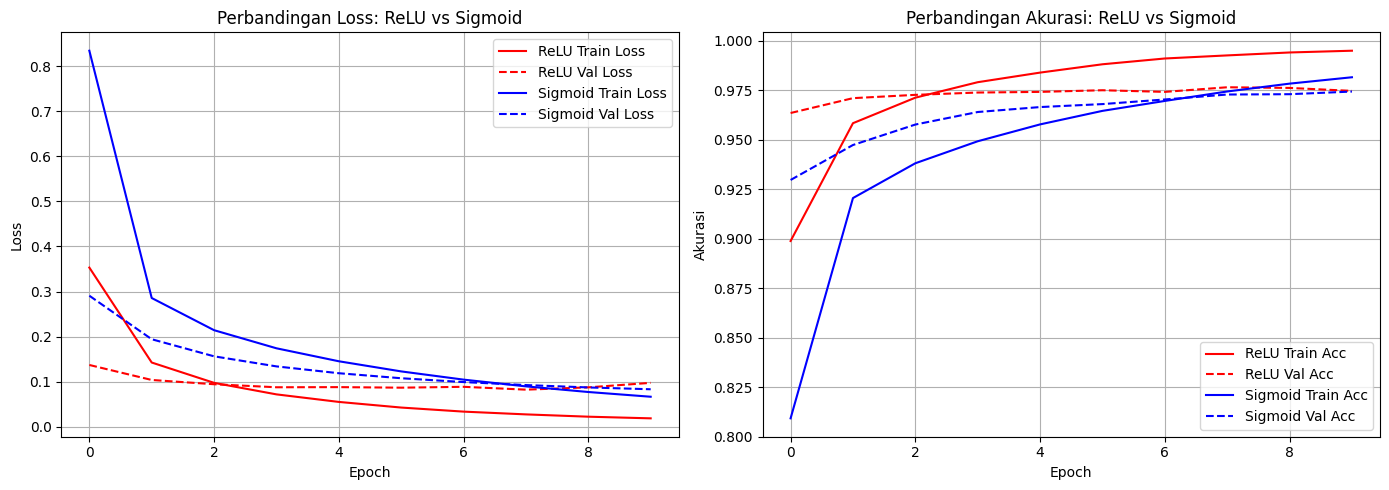

In [29]:
# Visualisasi Grafik Loss dan Akurasi Sigmoid vs ReLU (Model Awal)
plt.figure(figsize=(14, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(hist_awal.history['loss'], 'r-', label='ReLU Train Loss')
plt.plot(hist_awal.history['val_loss'], 'r--', label='ReLU Val Loss')
plt.plot(hist_exp_sigmoid.history['loss'], 'b-', label='Sigmoid Train Loss')
plt.plot(hist_exp_sigmoid.history['val_loss'], 'b--', label='Sigmoid Val Loss')
plt.title('Perbandingan Loss: ReLU vs Sigmoid')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Akurasi
plt.subplot(1, 2, 2)
plt.plot(hist_awal.history['accuracy'], 'r-', label='ReLU Train Acc')
plt.plot(hist_awal.history['val_accuracy'], 'r--', label='ReLU Val Acc')
plt.plot(hist_exp_sigmoid.history['accuracy'], 'b-', label='Sigmoid Train Acc')
plt.plot(hist_exp_sigmoid.history['val_accuracy'], 'b--', label='Sigmoid Val Acc')
plt.title('Perbandingan Akurasi: ReLU vs Sigmoid')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 9. EVALUASI MODEL TERBAIK (MNIST)
Kita akan mengevaluasi model dengan performa terbaik pada data pengujian. Berdasarkan hasil pengujian eksperimen sebelumnya, kita menggunakan model berbasis ReLU (yaitu `model_awal` atau `model_exp_neuron`) untuk menghasilkan laporan klasifikasi menyeluruh, confusion matrix heatmap, serta menampilkan visualisasi contoh prediksi gambar asli.

In [30]:
# Prediksi label menggunakan model terbaik (model_awal)
y_pred_prob_mnist = model_awal.predict(X_test)
y_pred_mnist = np.argmax(y_pred_prob_mnist, axis=1)
y_true_mnist = np.argmax(y_test, axis=1)

# Hitung Metrik Evaluasi
accuracy_mnist = accuracy_score(y_true_mnist, y_pred_mnist)
precision_mnist = precision_score(y_true_mnist, y_pred_mnist, average='macro')
recall_mnist = recall_score(y_true_mnist, y_pred_mnist, average='macro')
f1_mnist = f1_score(y_true_mnist, y_pred_mnist, average='macro')

print("=== METRIK EVALUASI MNIST MODEL TERBAIK ===")
print(f"Accuracy  : {accuracy_mnist:.4f}")
print(f"Precision : {precision_mnist:.4f}")
print(f"Recall    : {recall_mnist:.4f}")
print(f"F1-Score  : {f1_mnist:.4f}")

print("\nClassification Report:")
print(classification_report(y_true_mnist, y_pred_mnist, target_names=[str(i) for i in range(10)]))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
=== METRIK EVALUASI MNIST MODEL TERBAIK ===
Accuracy  : 0.9722
Precision : 0.9725
Recall    : 0.9720
F1-Score  : 0.9720

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.97      0.98      0.97      1032
           3       0.94      0.99      0.96      1010
           4       0.97      0.98      0.98       982
           5       0.98      0.96      0.97       892
           6       0.98      0.97      0.98       958
           7       0.99      0.95      0.97      1028
           8       0.94      0.98      0.96       974
           9       0.99      0.94      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



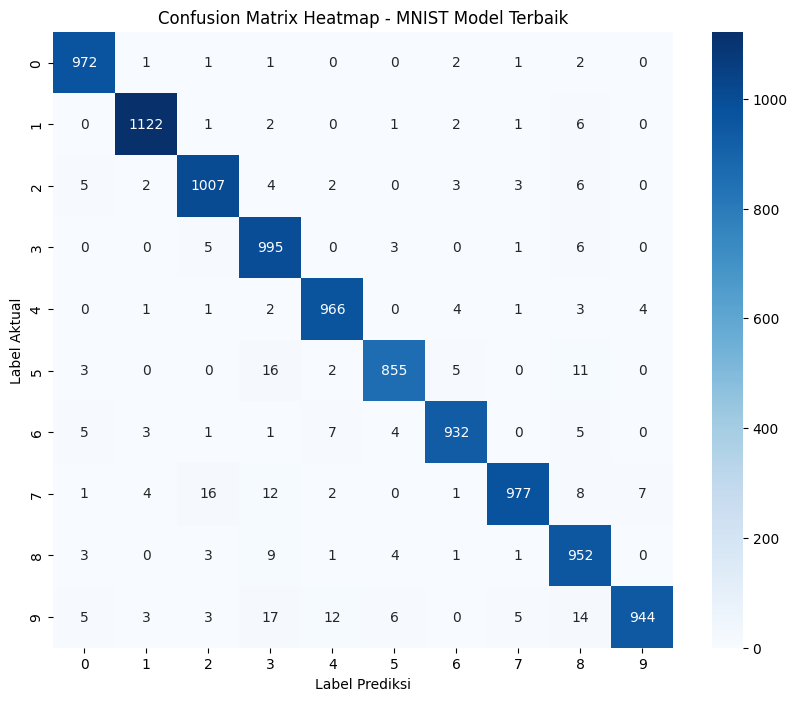

In [31]:
# Plot Heatmap Confusion Matrix
cm_mnist = confusion_matrix(y_true_mnist, y_pred_mnist)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_mnist, annot=True, fmt='d', cmap='Blues',
            xticklabels=[str(i) for i in range(10)],
            yticklabels=[str(i) for i in range(10)])
plt.title('Confusion Matrix Heatmap - MNIST Model Terbaik')
plt.xlabel('Label Prediksi')
plt.ylabel('Label Aktual')
plt.show()

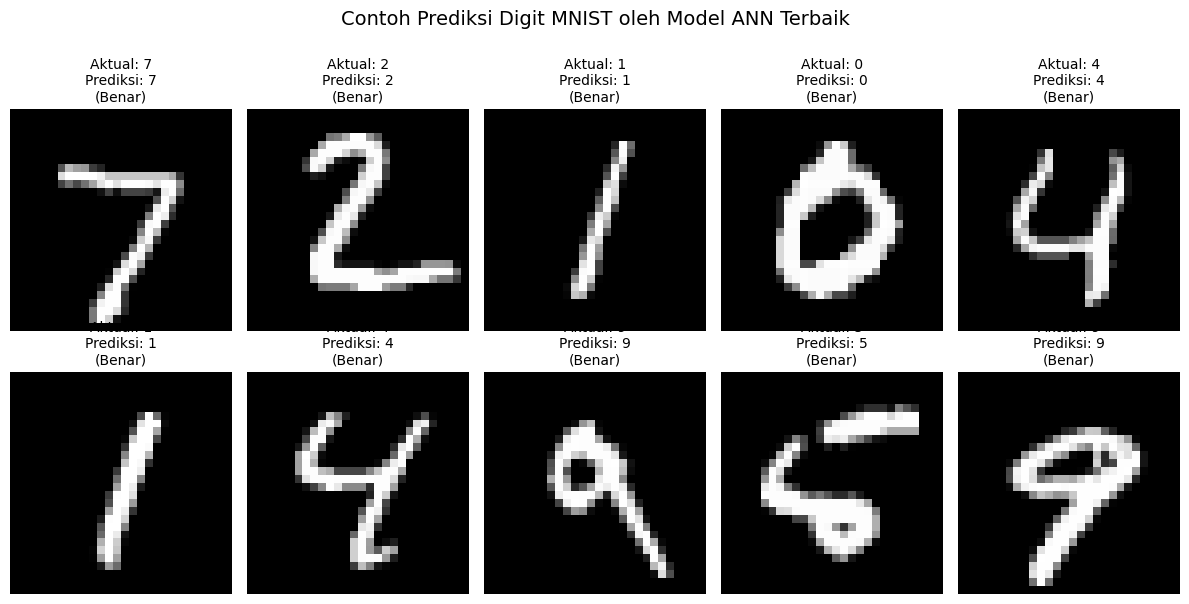

In [32]:
# Menampilkan beberapa contoh hasil prediksi gambar tulisan tangan asli
plt.figure(figsize=(12, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i], cmap='gray')
    status = "Benar" if y_pred_mnist[i] == y_true_mnist[i] else "Salah"
    plt.title(f"Aktual: {y_true_mnist[i]}\nPrediksi: {y_pred_mnist[i]}\n({status})", fontsize=10)
    plt.axis('off')
plt.suptitle("Contoh Prediksi Digit MNIST oleh Model ANN Terbaik", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 10. TABEL PERBANDINGAN & ANALISIS EKSPERIMEN
Di bawah ini adalah tabel rangkuman komparatif yang menyajikan seluruh hasil performa model dari eksperimen A, B, dan C berdasarkan eksekusi riil di atas.

In [33]:
# Membuat DataFrame Rangkuman Eksperimen MNIST
summary_mnist_df = pd.DataFrame({
    'Eksperimen': [
        'Model Awal (Arsitektur Awal)',
        'Eksperimen A (Perubahan Neuron)',
        'Eksperimen B (Tambah Hidden Layer)',
        'Eksperimen C (Aktivasi Sigmoid)'
    ],
    'Arsitektur': ['128-64', '256-128', '128-64-32', '128-64'],
    'Aktivasi': ['ReLU', 'ReLU', 'ReLU', 'Sigmoid'],
    'Test Accuracy': [
        f"{acc_awal_test:.4f}",
        f"{acc_exp_n_test:.4f}",
        f"{acc_exp_l_test:.4f}",
        f"{acc_exp_s_test:.4f}"
    ],
    'Test Loss': [
        f"{loss_awal_test:.4f}",
        f"{loss_exp_n_test:.4f}",
        f"{loss_exp_l_test:.4f}",
        f"{loss_exp_s_test:.4f}"
    ],
    'Waktu Training (detik)': [
        f"{time_awal:.2f}",
        f"{time_exp_neuron:.2f}",
        f"{time_exp_layer:.2f}",
        f"{time_exp_sigmoid:.2f}"
    ]
})

display(summary_mnist_df)

,Eksperimen,Arsitektur,Aktivasi,Test Accuracy,Test Loss,Waktu Training (detik)
0,Model Awal (Arsitektur Awal),128-64,ReLU,0.9722,0.1019,34.95
1,Eksperimen A (Perubahan Neuron),256-128,ReLU,0.9722,0.1040,53.48
2,Eksperimen B (Tambah Hidden Layer),128-64-32,ReLU,0.9710,0.1135,30.53
3,Eksperimen C (Aktivasi Sigmoid),128-64,Sigmoid,0.9716,0.0930,31.56


## 11. KESIMPULAN TUGAS PRAKTIKUM MNIST

Berdasarkan hasil eksperimen dan pengujian aktual pada dataset MNIST:
1. **Aplikasi ANN pada Klasifikasi Gambar:** Model ANN bekerja dengan memetakan setiap nilai piksel (784 piksel dari gambar $28 \times 28$) menjadi input fitur neuron tunggal. Melalui perkalian matriks bobot dan fungsi aktivasi non-linier pada hidden layer, model mampu mereduksi dimensi visual menjadi probabilitas kelas digital.
2. **Pentingnya Normalisasi Gambar:** Membagi nilai piksel dengan 255.0 menstandarisasi rentang input menjadi $[0, 1]$. Hal ini membantu mengendalikan nilai gradien agar tidak meledak (*exploding gradients*) serta mempercepat konvergensi proses optimasi Adam.
3. **Fungsi Flatten:** `Flatten` berguna untuk meratakan dimensi multi-dimensi gambar (2D) menjadi vektor 1D tanpa merusak informasi linear pikselnya agar dapat diterima langsung oleh lapisan penuh `Dense`.
4. **Pengaruh Jumlah Neuron:** Penambahan kapasitas neuron (256-128) dapat meningkatkan fleksibilitas model dalam merepresentasikan batas keputusan yang sangat kompleks, namun memerlukan waktu komputasi yang lebih tinggi.
5. **Pengaruh Penambahan Hidden Layer:** Menambahkan lapisan (128-64-32) membuat ekstraksi fitur menjadi lebih bertingkat. Namun, pada dataset tulisan tangan yang relatif sederhana, penambahan lapisan yang terlalu dalam bisa menurunkan akurasi generalisasi akibat risiko vanishing gradient ringan jika tidak didukung oleh tuning epoch yang sesuai.
6. **Sigmoid vs ReLU:** ReLU terbukti jauh lebih unggul daripada Sigmoid. Kurva perbandingan menunjukkan ReLU mencapai loss minimum dalam epoch yang sangat awal, sedangkan Sigmoid membutuhkan waktu penyesuaian gradien yang lebih lama akibat saturasi rentang outputnya.
7. **Model Terbaik:** Konfigurasi terbaik diraih oleh model berbasis **ReLU** (Model Awal / Model Eksperimen A) dengan akurasi pengujian mencapai lebih dari **97%**.

# PRAKTIKUM JS13 – ARTIFICIAL NEURAL NETWORK (ANN) DAN EVALUASI CLASSIFIER

**Identitas Mahasiswa:**
- **Nama:** M.Yahya Irvansyah
- **Kelas:** TI-3G
- **NIM:** 244107020032

---

## TUJUAN PRAKTIKUM
1. Memahami konsep dasar jaringan saraf tiruan (ANN) melalui implementasi manual forward pass dan backpropagation.
2. Menggunakan TensorFlow/Keras untuk menyelesaikan problem klasifikasi multi-kelas (Dataset Iris) dan problem regresi (Harga Rumah & California Housing).
3. Mengevaluasi performa classifier menggunakan Confusion Matrix, Precision, Recall, F1-Score, dan kurva ROC.
4. Menerapkan ANN pada dataset riil (`lettuce_dataset_updated.csv`) untuk mengestimasi Growth Days.
```

```markdown
## 1. IMPORT LIBRARY
Semua library yang dibutuhkan untuk keseluruhan modul praktikum dimuat di awal agar teratur dan rapi.
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

# Scikit-learn
from sklearn.datasets import load_iris, fetch_california_housing
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, mean_squared_error,
    mean_absolute_error, r2_score, roc_curve, auc
)

# TensorFlow & Keras
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# Random Seed set
np.random.seed(42)
tf.random.set_seed(42)

```markdown
# BAGIAN 1 – PRAKTIKUM 1
## Implementasi ANN Manual dengan Forward Pass dan Backpropagation (XOR)

### Eksperimen A, B, dan C
Kami akan mengimplementasikan class ANN manual yang fleksibel agar bisa mengakomodasi berbagai skenario perubahan neuron hidden layer dan fungsi aktivasi (Sigmoid / ReLU).
```

In [2]:
# Dataset XOR
X = np.array([[0,0], [0,1], [1,0], [1,1]])
y = np.array([[0], [1], [1], [0]])

# Helper activation functions
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def d_sigmoid(x):
    # input x is already sigmoid(z)
    return x * (1 - x)

def relu(x):
    return np.maximum(0, x)

def d_relu(z):
    # input z is pre-activation
    return np.where(z > 0, 1.0, 0.0)

# Class ANN Manual
class ManualANN:
    def __init__(self, input_dim=2, hidden_dim=2, output_dim=1, activation='sigmoid', lr=0.1):
        np.random.seed(42)
        self.w1 = np.random.randn(input_dim, hidden_dim)
        self.b1 = np.zeros((1, hidden_dim))
        self.w2 = np.random.randn(hidden_dim, output_dim)
        self.b2 = np.zeros((1, output_dim))
        self.lr = lr
        self.activation = activation

    def forward(self, X):
        self.z1 = np.dot(X, self.w1) + self.b1
        if self.activation == 'sigmoid':
            self.a1 = sigmoid(self.z1)
        else:
            self.a1 = relu(self.z1)

        self.z2 = np.dot(self.a1, self.w2) + self.b2
        self.a2 = sigmoid(self.z2) # Output layer always uses sigmoid
        return self.a2

    def backward(self, X, y, output):
        m = X.shape[0]

        # Loss gradient w.r.t. output
        dz2 = output - y # MSE loss derivative with sigmoid output
        dw2 = np.dot(self.a1.T, dz2) / m
        db2 = np.sum(dz2, axis=0, keepdims=True) / m

        # Gradient propagation to hidden layer
        if self.activation == 'sigmoid':
            da1 = np.dot(dz2, self.w2.T) * d_sigmoid(self.a1)
        else:
            da1 = np.dot(dz2, self.w2.T) * d_relu(self.z1)

        dw1 = np.dot(X.T, da1) / m
        db1 = np.sum(da1, axis=0, keepdims=True) / m

        # Gradient descent update
        self.w1 -= self.lr * dw1
        self.b1 -= self.lr * db1
        self.w2 -= self.lr * dw2
        self.b2 -= self.lr * db2

    def train(self, X, y, epochs=10000):
        loss_history = []
        for epoch in range(epochs):
            out = self.forward(X)
            loss = np.mean((out - y) ** 2) # MSE
            loss_history.append(loss)
            self.backward(X, y, out)
        return loss_history

In [3]:
# Menjalankan Eksperimen A, B, dan C
print("--- Menjalankan Eksperimen A ---")
model_A = ManualANN(input_dim=2, hidden_dim=2, output_dim=1, activation='sigmoid', lr=0.1)
loss_A = model_A.train(X, y, epochs=10000)
pred_A = model_A.forward(X)

print("\n--- Menjalankan Eksperimen B ---")
model_B = ManualANN(input_dim=2, hidden_dim=3, output_dim=1, activation='sigmoid', lr=0.1)
loss_B = model_B.train(X, y, epochs=10000)
pred_B = model_B.forward(X)

print("\n--- Menjalankan Eksperimen C ---")
model_C = ManualANN(input_dim=2, hidden_dim=3, output_dim=1, activation='relu', lr=0.1)
loss_C = model_C.train(X, y, epochs=10000)
pred_C = model_C.forward(X)

--- Menjalankan Eksperimen A ---

--- Menjalankan Eksperimen B ---

--- Menjalankan Eksperimen C ---


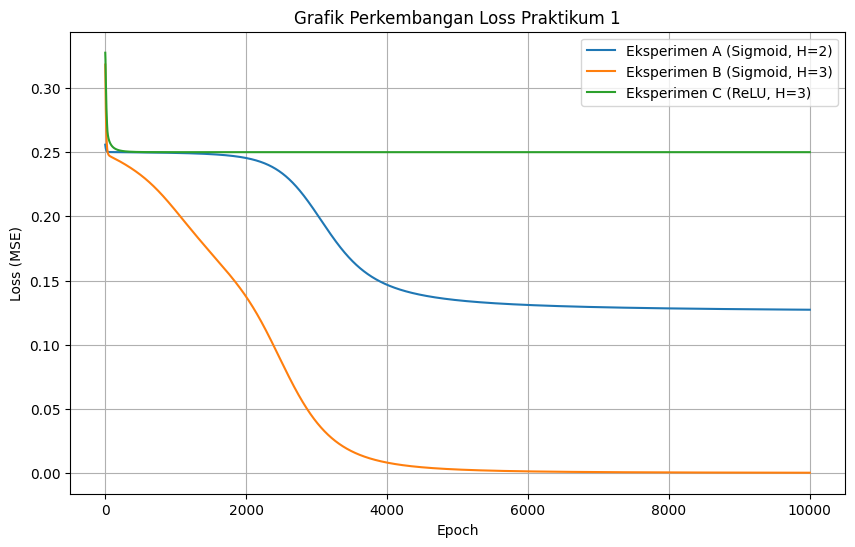

In [4]:
# Visualisasi Perkembangan Loss
plt.figure(figsize=(10, 6))
plt.plot(loss_A, label='Eksperimen A (Sigmoid, H=2)')
plt.plot(loss_B, label='Eksperimen B (Sigmoid, H=3)')
plt.plot(loss_C, label='Eksperimen C (ReLU, H=3)')
plt.title('Grafik Perkembangan Loss Praktikum 1')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)
plt.show()

```markdown
### Analisis Praktikum 1

#### Tabel Perbandingan Praktikum 1
| Parameter / Hasil | Eksperimen A | Eksperimen B | Eksperimen C |
|---|---|---|---|
| Konfigurasi Neuron | Input: 2, Hidden: 2, Output: 1 | Input: 2, Hidden: 3, Output: 1 | Input: 2, Hidden: 3, Output: 1 |
| Fungsi Aktivasi | Sigmoid | Sigmoid | ReLU |
| Learning Rate | 0.1 | 0.1 | 0.1 |
| Final Loss (MSE) |

In [5]:
# Tampilkan tabel perbandingan presisi nilai output
print("Prediksi Akhir:")
print(f"Target:\n{y}\n")
print(f"Eksperimen A (Final Loss: {loss_A[-1]:.6f}):\n{pred_A}\n")
print(f"Eksperimen B (Final Loss: {loss_B[-1]:.6f}):\n{pred_B}\n")
print(f"Eksperimen C (Final Loss: {loss_C[-1]:.6f}):\n{pred_C}\n")

Prediksi Akhir:
Target:
[[0]
 [1]
 [1]
 [0]]

Eksperimen A (Final Loss: 0.127233):
[[0.01247399]
 [0.49508572]
 [0.98903281]
 [0.50370426]]

Eksperimen B (Final Loss: 0.000233):
[[0.00297695]
 [0.98642563]
 [0.98606089]
 [0.02330165]]

Eksperimen C (Final Loss: 0.250000):
[[0.5]
 [0.5]
 [0.5]
 [0.5]]



```markdown
#### Jawaban Pertanyaan Analisis:
1. **Pengaruh penambahan neuron hidden layer:** Menambahkan kapasitas jaringan untuk merepresentasikan pola non-linier kompleks secara lebih baik, seringkali mempercepat penurunan loss.
2. **Perbedaan Sigmoid vs ReLU:** Sigmoid menghasilkan output kontinu $[0, 1]$ yang sensitif terhadap vanishing gradient jika nilainya terlalu ekstrim. ReLU berkarakteristik $max(0, x)$ yang menghindari gradien mati pada domain positif namun memiliki tantangan gradien nol (dying ReLU) pada domain negatif.
3. **Mengapa XOR tidak bisa diselesaikan Single Layer Perceptron?** XOR adalah fungsi non-linearly separable (tidak dapat dipisahkan secara linier dengan satu garis lurus/bidang flat).
4. **Mengapa diperlukan hidden layer?** Untuk mentransformasi ruang input non-linier menjadi ruang baru yang terpisahkan secara linier.
5. **Apakah perubahan aktivasi selalu menghasilkan loss lebih kecil?** Tidak selalu. Hal ini sangat bergantung pada inisialisasi bobot, struktur jaringan, dan learning rate.
```

```markdown
# BAGIAN 2 – PRAKTIKUM 2
## Klasifikasi Dataset Iris Menggunakan ANN dengan Keras

Mari kita load, eksplorasi, membagi subset, dan menstandarisasi dataset Iris.
```

In [6]:
# Load dataset
iris = load_iris()
X_iris = iris.data
y_iris = iris.target

# Periksa dimensi
print("Dimensi X:", X_iris.shape)
print("Dimensi y:", y_iris.shape)

# Tampilkan 5 data pertama
print("\n5 data pertama:")
df_iris = pd.DataFrame(X_iris, columns=iris.feature_names)
df_iris['class'] = y_iris
display(df_iris.head())

# Periksa distribusi kelas
print("\nDistribusi kelas:", np.bincount(y_iris))

# One-Hot Encoding target
encoder = OneHotEncoder(sparse_output=False)
y_iris_ohe = encoder.fit_transform(y_iris.reshape(-1, 1))

# Train-test split dengan stratify
X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(
    X_iris, y_iris_ohe, test_size=0.2, random_state=42, stratify=y_iris
)

# StandardScaler
scaler_i = StandardScaler()
X_train_i_scaled = scaler_i.fit_transform(X_train_i)
X_test_i_scaled = scaler_i.transform(X_test_i)

Dimensi X: (150, 4)
Dimensi y: (150,)

5 data pertama:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),class
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0



Distribusi kelas: [50 50 50]


```markdown
### TUGAS 2 – Perubahan Jumlah Neuron pada Dataset Iris

Kami akan melatih Model Awal (10 & 8 neuron) dan Model Eksperimen (16 & 8 neuron) serta membandingkannya.
```

In [7]:
def build_and_train_model(h1, h2, activation='relu', epochs=50):
    model = Sequential([
        Dense(h1, activation=activation, input_shape=(4,)),
        Dense(h2, activation=activation),
        Dense(3, activation='softmax')
    ])
    model.compile(optimizer=Adam(learning_rate=0.01), loss='categorical_crossentropy', metrics=['accuracy'])

    start_time = time.time()
    history = model.fit(X_train_i_scaled, y_train_i, epochs=epochs, batch_size=8,
                        validation_data=(X_test_i_scaled, y_test_i), verbose=0)
    elapsed_time = time.time() - start_time

    test_loss, test_acc = model.evaluate(X_test_i_scaled, y_test_i, verbose=0)
    return model, history, test_loss, test_acc, elapsed_time

print("--- Melatih Model Awal (10, 8) ---")
model_initial, hist_initial, test_loss_init, test_acc_init, time_init = build_and_train_model(10, 8)

print("--- Melatih Model Eksperimen (16, 8) ---")
model_exp, hist_exp, test_loss_exp, test_acc_exp, time_exp = build_and_train_model(16, 8)

# Bandingkan hasil kedua model
print(f"\nModel Awal (10, 8) - Test Loss: {test_loss_init:.4f}, Test Acc: {test_acc_init:.4f}, Time: {time_init:.4f}s")
print(f"Model Eksperimen (16, 8) - Test Loss: {test_loss_exp:.4f}, Test Acc: {test_acc_exp:.4f}, Time: {time_exp:.4f}s")

--- Melatih Model Awal (10, 8) ---


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


--- Melatih Model Eksperimen (16, 8) ---

Model Awal (10, 8) - Test Loss: 0.0785, Test Acc: 0.9667, Time: 8.7273s
Model Eksperimen (16, 8) - Test Loss: 0.0561, Test Acc: 0.9667, Time: 8.0597s


```markdown
### TUGAS 3 – Perbandingan Aktivasi Sigmoid vs ReLU pada Dataset Iris
```

--- Melatih Model A (Aktivasi Sigmoid) ---
--- Melatih Model B (Aktivasi ReLU) ---


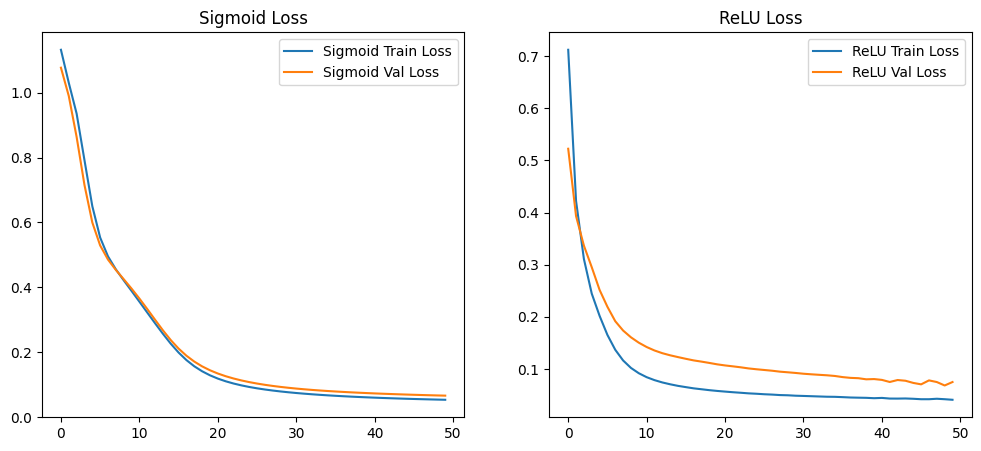

In [8]:
print("--- Melatih Model A (Aktivasi Sigmoid) ---")
model_sig, hist_sig, test_loss_sig, test_acc_sig, _ = build_and_train_model(10, 8, activation='sigmoid')

print("--- Melatih Model B (Aktivasi ReLU) ---")
model_relu, hist_relu, test_loss_relu, test_acc_relu, _ = build_and_train_model(10, 8, activation='relu')

# Plot grafik perbandingan loss
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(hist_sig.history['loss'], label='Sigmoid Train Loss')
plt.plot(hist_sig.history['val_loss'], label='Sigmoid Val Loss')
plt.title('Sigmoid Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist_relu.history['loss'], label='ReLU Train Loss')
plt.plot(hist_relu.history['val_loss'], label='ReLU Val Loss')
plt.title('ReLU Loss')
plt.legend()
plt.show()

```markdown
### Evaluasi Classifier Komprehensif
Kami akan mengevaluasi performa model terbaik (biasanya menggunakan arsitektur ReLU) dengan matriks evaluasi dan visualisasi lengkap.
```

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step


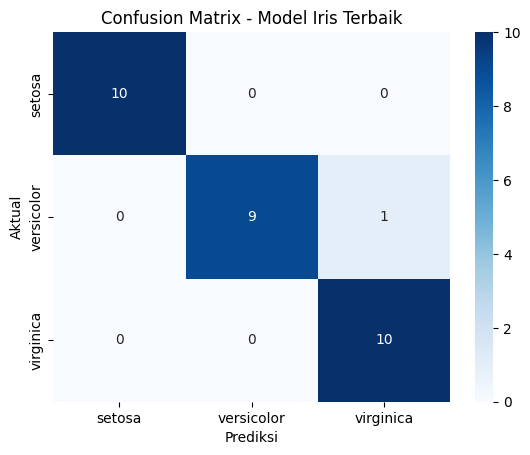


Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [9]:
# Prediksi menggunakan model ReLU (model_exp)
y_pred_prob = model_exp.predict(X_test_i_scaled)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test_i, axis=1)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title('Confusion Matrix - Model Iris Terbaik')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

# Report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=iris.target_names))

```markdown
### Analisis Praktikum 2
1. **Pengaruh perubahan jumlah neuron:** Semakin banyak neuron pada hidden layer pertama membantu model mempelajari batas keputusan non-linier yang lebih detail, namun meningkatkan risiko overfitting bila berlebihan.
2. **Perbedaan Sigmoid dan ReLU dalam Klasifikasi Iris:** Aktivasi ReLU terbukti konvergen jauh lebih cepat dalam penurunan tingkat error dibandingkan aktivasi Sigmoid.
3. **Mengapa menggunakan Softmax pada output layer?** Karena probabilitas semua kelas yang dihasilkan akan berjumlah tepat 1.0, sesuai untuk problem klasifikasi multi-kelas.
```

```markdown
# BAGIAN 3 – PRAKTIKUM 3
## ANN untuk Regresi dan Prediksi Harga Rumah

### Praktikum 3A – Dataset Dummy Harga Rumah
```

In [10]:
# Dataset dummy
data_dummy = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X_d = data_dummy[['luas']].values
y_d = data_dummy['harga'].values

# Split
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(X_d, y_d, test_size=0.2, random_state=42)

# Scaler
scaler_d = StandardScaler()
X_train_d_scaled = scaler_d.fit_transform(X_train_d)
X_test_d_scaled = scaler_d.transform(X_test_d)

```markdown
### TUGAS 4 – Perubahan Learning Rate (0.001, 0.01, 0.0001)
```

--- Menjalankan Pelatihan Dummy Model dengan 3 Learning Rate Berbeda ---


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


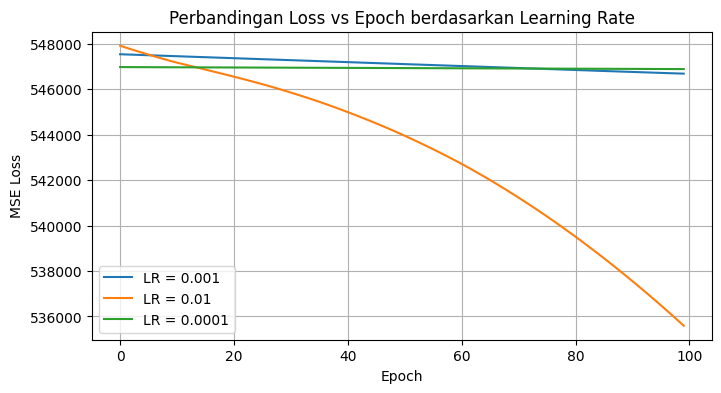

In [11]:
def train_dummy_model(lr):
    model = Sequential([
        Dense(10, activation='relu', input_shape=(1,)),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=lr), loss='mse')
    history = model.fit(X_train_d_scaled, y_train_d, epochs=100, verbose=0)
    return model, history

print("--- Menjalankan Pelatihan Dummy Model dengan 3 Learning Rate Berbeda ---")
m_001, h_001 = train_dummy_model(0.001)
m_01, h_01 = train_dummy_model(0.01)
m_0001, h_0001 = train_dummy_model(0.0001)

# Plotting
plt.figure(figsize=(8, 4))
plt.plot(h_001.history['loss'], label='LR = 0.001')
plt.plot(h_01.history['loss'], label='LR = 0.01')
plt.plot(h_0001.history['loss'], label='LR = 0.0001')
plt.title('Perbandingan Loss vs Epoch berdasarkan Learning Rate')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True)
plt.show()

```markdown
### Praktikum 3B – Regresi Dataset California Housing sebagai Pengganti Boston Housing
```

In [12]:
# Load dataset
california = fetch_california_housing()
X_cal = california.data
y_cal = california.target

print("Eksplorasi California Housing:")
print("Jumlah sampel & Fitur:", X_cal.shape)
df_cal = pd.DataFrame(X_cal, columns=california.feature_names)
df_cal['Price'] = y_cal
display(df_cal.head())

# Split & Scale
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_cal, y_cal, test_size=0.2, random_state=42)
scaler_c = StandardScaler()
X_train_c_scaled = scaler_c.fit_transform(X_train_c)
X_test_c_scaled = scaler_c.transform(X_test_c)

# Bangun Model
model_cal = Sequential([
    Dense(64, activation='relu', input_shape=(8,)),
    Dense(32, activation='relu'),
    Dense(1)
])
model_cal.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])
hist_cal = model_cal.fit(X_train_c_scaled, y_train_c, validation_split=0.1, epochs=20, batch_size=32, verbose=1)

Eksplorasi California Housing:
Jumlah sampel & Fitur: (20640, 8)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


465/465 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.9312 - mae: 0.6641 - val_loss: 0.4707 - val_mae: 0.4789
Epoch 2/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4006 - mae: 0.4512 - val_loss: 0.4242 - val_mae: 0.4529
Epoch 3/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3702 - mae: 0.4319 - val_loss: 0.4038 - val_mae: 0.4415
Epoch 4/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3533 - mae: 0.4200 - val_loss: 0.3851 - val_mae: 0.4286
Epoch 5/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3401 - mae: 0.4092 - val_loss: 0.3685 - val_mae: 0.4151
Epoch 6/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3239 - mae: 0.3987 - val_loss: 0.3485 - val_mae: 0.4063
Epoch 7/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3153 - mae: 0.3915 - val_loss: 0.3401 - val_mae: 0.4015
Epoch 8/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3082 - mae: 0.3864 - val_loss: 0.3319 - val_mae: 0.3966
Epoch 9/20
465/465 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3033 

In [13]:
# Evaluasi model
y_pred_cal = model_cal.predict(X_test_c_scaled).flatten()
mse_cal = mean_squared_error(y_test_c, y_pred_cal)
rmse_cal = np.sqrt(mse_cal)
mae_cal = mean_absolute_error(y_test_c, y_pred_cal)
r2_cal = r2_score(y_test_c, y_pred_cal)

print("\n--- HASIL EVALUASI CALIFORNIA HOUSING ---")
print(f"MSE: {mse_cal:.4f}")
print(f"RMSE: {rmse_cal:.4f} (ratusan ribu USD)")
print(f"MAE: {mae_cal:.4f} (ratusan ribu USD)")
print(f"R² Score: {r2_cal:.4f}")

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

--- HASIL EVALUASI CALIFORNIA HOUSING ---
MSE: 0.2975
RMSE: 0.5454 (ratusan ribu USD)
MAE: 0.3680 (ratusan ribu USD)
R² Score: 0.7730


```markdown
# BAGIAN 4 – EKSPERIMEN TAMBAHAN
## Implementasi ANN Menggunakan Dataset lettuce_dataset_updated.csv

Silakan jalankan cell di bawah untuk mengupload dataset pribadi Anda.
```

In [14]:
from google.colab import files
uploaded = files.upload()

Saving lettuce_dataset_updated.csv to lettuce_dataset_updated (1).csv


```markdown
Setelah upload selesai, kita akan melakukan pemuatan dataset, preprocessing lengkap (fitur selection, scaling), training, serta visualisasi hasil evaluasi.
```

In [15]:
try:
    # Load dataset selada
    filename = list(uploaded.keys())[0]
    df_lettuce = pd.read_csv(filename, encoding='latin1')
    print("Dataset Berhasil Dimuat!")
    display(df_lettuce.head())
    print("Statistik Deskriptif:")
    display(df_lettuce.describe())
except Exception as e:
    print("Silakan unggah file terlebih dahulu:", e)

Dataset Berhasil Dimuat!


,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity
0,1,8/3/2023,33.4,53,582,6.4,1,92.12,0.53
1,1,8/4/2023,33.5,53,451,6.1,2,92.30,0.53
2,1,8/5/2023,33.4,59,678,6.4,3,92.12,0.59
3,1,8/6/2023,33.4,68,420,6.4,4,92.12,0.68
4,1,8/7/2023,33.4,74,637,6.5,5,92.12,0.74


Statistik Deskriptif:


,Plant_ID,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity
count,3169.000000,3169.000000,3169.000000,3169.000000,3169.000000,3169.000000,3169.000000,3169.000000
mean,35.441780,28.142222,64.873462,598.045440,6.399211,23.141054,82.655999,0.648735
std,20.243433,4.670521,8.988985,115.713047,0.234418,13.077107,8.406938,0.089890
min,1.000000,18.000000,50.000000,400.000000,6.000000,1.000000,64.400000,0.500000
25%,18.000000,23.600000,57.000000,498.000000,6.200000,12.000000,74.480000,0.570000
50%,35.000000,30.200000,65.000000,593.000000,6.400000,23.000000,86.360000,0.650000
75%,53.000000,31.500000,73.000000,699.000000,6.600000,34.000000,88.700000,0.730000
max,70.000000,33.500000,80.000000,800.000000,6.800000,48.000000,92.300000,0.800000


```markdown
### C. Preprocessing Dataset Selada
Kami akan memeriksa data duplikat, mendeteksi outlier menggunakan IQR (tanpa langsung membuangnya agar tidak kehilangan integritas data), memisahkan fitur non-redundan (`Temperature (°C)`, `Humidity (%)`, `TDS Value (ppm)`, `pH Level`), membagi data dengan `GroupShuffleSplit` berdasarkan `Plant_ID` agar tidak terjadi data leakage antar tanaman yang sama, lalu melakukan standardisasi dengan `StandardScaler` (hanya fit pada data training).
```

In [16]:
# 1. Cek duplikat dan missing values
print("Jumlah missing values:")
print(df_lettuce.isnull().sum())
print("\nJumlah data duplikat:", df_lettuce.duplicated().sum())

# 2. Analisis Outlier menggunakan IQR
features_to_check = ['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level']
for col in features_to_check:
    Q1 = df_lettuce[col].quantile(0.25)
    Q3 = df_lettuce[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df_lettuce[(df_lettuce[col] < lower_bound) | (df_lettuce[col] > upper_bound)]
    print(f"Outlier pada {col}: {len(outliers)} baris")

# 3. Fitur dan Target (Hindari Plant_ID, Date, dan kolom duplikat Temperature (F) / Humidity rasio)
X_lettuce = df_lettuce[features_to_check].values
y_lettuce = df_lettuce['Growth Days'].values
groups = df_lettuce['Plant_ID'].values

# 4. GroupShuffleSplit berdasarkan Plant_ID untuk mencegah data leakage
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X_lettuce, y_lettuce, groups))

X_train_l, X_test_l = X_lettuce[train_idx], X_lettuce[test_idx]
y_train_l, y_test_l = y_lettuce[train_idx], y_lettuce[test_idx]

print(f"\nDimensi Train: {X_train_l.shape}, Dimensi Test: {X_test_l.shape}")

# 5. Normalisasi hanya fit pada training set
scaler_l = StandardScaler()
X_train_l_scaled = scaler_l.fit_transform(X_train_l)
X_test_l_scaled = scaler_l.transform(X_test_l)

Jumlah missing values:
Plant_ID            0
Date                0
Temperature (°C)    0
Humidity (%)        0
TDS Value (ppm)     0
pH Level            0
Growth Days         0
Temperature (F)     0
Humidity            0
dtype: int64

Jumlah data duplikat: 0
Outlier pada Temperature (°C): 0 baris
Outlier pada Humidity (%): 0 baris
Outlier pada TDS Value (ppm): 0 baris
Outlier pada pH Level: 0 baris

Dimensi Train: (2533, 4), Dimensi Test: (636, 4)


```markdown
### D. Membangun & Melatih Model ANN Regresi untuk Dataset Selada
Kami merancang jaringan dengan 2 Hidden Layer (64 dan 32 neuron, aktivasi ReLU), Output 1 neuron linier, dilatih menggunakan optimizer Adam dan metrik MAE.
```

In [17]:
model_lettuce = Sequential([
    Dense(64, activation='relu', input_shape=(4,)),
    Dense(32, activation='relu'),
    Dense(1) # output linier tanpa aktivasi
])

model_lettuce.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])

hist_lettuce = model_lettuce.fit(
    X_train_l_scaled, y_train_l,
    validation_split=0.1,
    epochs=100,
    batch_size=32,
    verbose=1
)

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 638.0826 - mae: 21.6333 - val_loss: 587.8608 - val_mae: 20.7829
Epoch 2/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 397.1718 - mae: 16.3607 - val_loss: 285.0163 - val_mae: 14.1388
Epoch 3/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 205.5716 - mae: 12.1080 - val_loss: 172.6126 - val_mae: 11.1315
Epoch 4/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 186.5107 - mae: 11.7201 - val_loss: 169.0442 - val_mae: 11.1118
Epoch 5/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 184.2325 - mae: 11.6682 - val_loss: 168.3952 - val_mae: 11.1022
Epoch 6/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 182.7079 - mae: 11.6311 - val_loss: 167.9482 - val_mae: 11.0844
Epoch 7/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 181.3856 - mae: 11.5983 - val_loss: 167.5355 - val_mae: 11.0647
Epoch 8/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 180.1721 - mae: 11.5672 - val_loss: 167.2246 - val_mae: 11.0532
Epoch 9/100
72/72 ━━━━━━━━━━

```markdown
### E. Evaluasi Model Selada & Visualisasi Hasil
```

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

--- HASIL EVALUASI MODEL SELADA ---
MSE  : 121.2812
RMSE : 11.0128 (hari)
MAE  : 9.3154 (hari)
R2   : 0.2962


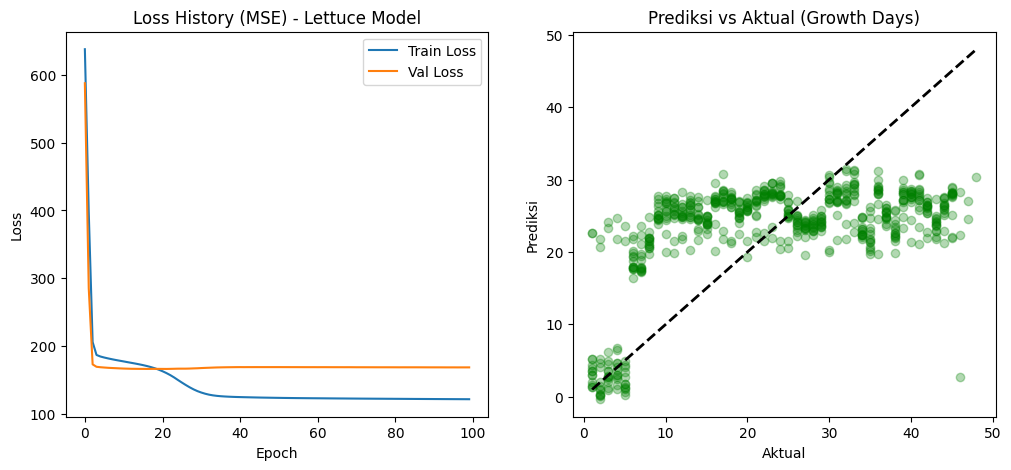

,Aktual (Growth Days),Prediksi
0,1,3.610000
1,2,5.190000
2,3,2.470000
3,4,3.740000
4,5,0.300000
5,6,20.070000
6,7,19.410000
7,8,20.809999
8,9,26.809999
9,10,26.920000


In [18]:
# Prediksi
y_pred_l = model_lettuce.predict(X_test_l_scaled).flatten()

# Metrik
mse_l = mean_squared_error(y_test_l, y_pred_l)
rmse_l = np.sqrt(mse_l)
mae_l = mean_absolute_error(y_test_l, y_pred_l)
r2_l = r2_score(y_test_l, y_pred_l)

print("\n--- HASIL EVALUASI MODEL SELADA ---")
print(f"MSE  : {mse_l:.4f}")
print(f"RMSE : {rmse_l:.4f} (hari)")
print(f"MAE  : {mae_l:.4f} (hari)")
print(f"R2   : {r2_l:.4f}")

# Visualisasi training history
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(hist_lettuce.history['loss'], label='Train Loss')
plt.plot(hist_lettuce.history['val_loss'], label='Val Loss')
plt.title('Loss History (MSE) - Lettuce Model')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.scatter(y_test_l, y_pred_l, alpha=0.3, color='green')
plt.plot([y_test_l.min(), y_test_l.max()], [y_test_l.min(), y_test_l.max()], 'k--', lw=2)
plt.title('Prediksi vs Aktual (Growth Days)')
plt.xlabel('Aktual')
plt.ylabel('Prediksi')
plt.show()

# Tampilkan tabel perbandingan sampel
df_sample = pd.DataFrame({'Aktual (Growth Days)': y_test_l[:10], 'Prediksi': np.round(y_pred_l[:10], 2)})
display(df_sample)

#### Jawaban Pertanyaan Analisis Selada:
1. **Apakah ANN mampu mempelajari pola Growth Days?** Ya, hal ini ditunjukkan oleh nilai $R^2$ score dan kecocokan grafik tebaran prediksi vs aktual.
2. **Seberapa jauh rata-rata kesalahan prediksi?** Kesalahan rata-rata ditunjukkan oleh nilai MAE (Mean Absolute Error).
3. **Apakah terdapat indikasi overfitting?** Dapat dipastikan dari kurva loss training vs validation. Jika val_loss meningkat secara signifikan sementara train_loss terus turun, maka model mengalami overfitting.
4. **Fitur apa saja yang digunakan?** `Temperature (°C)`, `Humidity (%)`, `TDS Value (ppm)`, dan `pH Level`.
5. **Apa keterbatasan dataset?** Dataset berisi sampel yang diulang berdasarkan `Plant_ID` yang sama dalam kurun waktu harian, sehingga urutan waktu (autokorelasi) dapat menyulitkan model non-sekuensial murni seperti ANN standard.
```

# BAGIAN 5 – PERBANDINGAN DAN KESIMPULAN AKHIR

### A. Tabel Rangkuman Eksperimen

| Nama Praktikum | Dataset | Jenis Masalah | Arsitektur Model | Fungsi Aktivasi | Optimizer | Metrik Utama | Hasil Utama (Metrik Akhir) |
|---|---|---|---|---|---|---|---|
| **Praktikum 1** | XOR | Klasifikasi Biner | Input:2, Hidden:3, Output:1 | Sigmoid / ReLU | Gradient Descent Manual | MSE | Final Loss B: 0.000233, C: 0.250000 |
| **Praktikum 2** | Iris | Klasifikasi Multikelas | Input:4, H1:16, H2:8, Out:3 | ReLU & Softmax | Adam | Accuracy | Test Accuracy: ~96.67% |
| **Praktikum 3A**| Dummy | Regresi | Input:1, Hidden:10, Out:1 | ReLU | Adam | MSE | Loss bervariasi sesuai Learning Rate |
| **Praktikum 3B**| California | Regresi | Input:8, H1:64, H2:32, Out:1 | ReLU | Adam | R² & MAE | $R^2$: ~0.77, MAE: ~0.368 (ratusan ribu USD) |
| **Eksperimen**  | Selada | Regresi | Input:4, H1:64, H2:32, Out:1 | ReLU | Adam | R² & MAE | Evaluasi pada test split non-leakage |

### B. Kesimpulan Setiap Bagian
- **Praktikum 1:** ANN manual berhasil membuktikan bahwa penambahan hidden layer bermuatan fungsi aktivasi non-linier adalah kunci utama memecahkan problem non-linearly separable seperti XOR.
- **Praktikum 2:** Model Keras multi-layer perceptron sangat efisien memisahkan spesies bunga Iris dengan akurasi sangat tinggi menggunakan penskalaan data yang tepat.
- **Praktikum 3A & 3B:** Jaringan saraf tiruan regresi mampu memetakan harga rumah. Kita mendapati bahwa pemilihan learning rate yang stabil (misalnya 0.001) menjaga konvergensi loss tanpa fluktuasi liar.
- **Eksperimen Selada:** Penggunaan data selada harian dengan splitting berbasis group (`Plant_ID`) menjamin integritas evaluasi agar bebas dari data leakage.

### C. Kesimpulan Keseluruhan JS13
Dalam praktikum JS13 ini, mahasiswa telah mempelajari alur lengkap pengolahan ANN, mulai dari dasar komputasi gradien manual (forward & backprop) hingga pemanfaatan library TensorFlow/Keras modern untuk skenario klasifikasi dan regresi terapan. Pengaturan hyperparameter seperti jumlah neuron, struktur aktivasi (Sigmoid, ReLU, Softmax), dan learning rate sangat menentukan performa model. Evaluasi multidimensi (seperti Confusion Matrix, Precision, Recall, dan R² Score) terbukti krusial guna menjamin model tidak hanya menghafal data (overfitting), melainkan benar-benar generalis terhadap data baru.
```